**Tópicos Selectos en Aprendizaje Maquinal - TP N°1: Algoritmos para Reconocimiento de Patrones**

**Estanislao Claucich**

### Ejercicio 10: Modelos de Markov

1. La Secretaria de Turismo de una ciudad quiere modelar el clima diario local para planificar distintas actividades. Para ello se propone el modelo probabilístico de la Figura 7 basado en autómatas observables de Markov, con los siguientes parámetros:
$$
\mathbf{A}=\begin{pmatrix}0.7&0.3\\0.4&0.6\end{pmatrix},\qquad \boldsymbol\pi=\begin{pmatrix}0.6&0.4\end{pmatrix}
$$
    
a) Realice la simulación computacional del mismo como modelo generativo.  
b) Genere varias secuencias climáticas y grafíquelas.  
c) Utilice las secuencias de salida generadas para re-estimar los valores de $\mathbf{A}$ y $\boldsymbol\pi$: ¿Cómo influye la cantidad de secuencias y el largo de las mismas en la estimación de los parámetros del autómata? ¿Sería este modelo válido para todas las estaciones del año?  
d) ¿Cómo convertiría este modelo en un modelo oculto de Markov? Realice los cambios que correspondan en la simulación para este caso, genere nuevas secuencias con este modelo y comente los resultados comparados con el caso anterior. (Puede comenzar suponiendo una matriz de probabilidades de observación tipo identidad (caso completamente observable) para luego "ocultar" progresivamente el modelo.)

2. La Secretaria de Turismo quiere ahora modelar la actividad principal diaria de los turistas que visitan la ciudad y su relación con el clima. Para ello se propone completar el modelo anterior para convertirlo en un modelo oculto de Markov como el de la Figura 8, con los siguientes parámetros:
$$
\mathbf{A}=\begin{pmatrix}0.7&0.3\\0.4&0.6\end{pmatrix},\qquad
\mathbf{B}=\begin{pmatrix}0.1&0.6\\0.4&0.3\\0.5&0.1\end{pmatrix},\qquad
\boldsymbol\pi=\begin{pmatrix}0.6&0.4\end{pmatrix}
$$

a) Genere una secuencia de comportamientos suficientemente larga y calcule la secuencia de climas más probable (para esa secuencia de comportamientos). ¿Cuánto difiere la secuencia climática "real" generada por el modelo de la estimada a partir de sus parámetros?  
b) Utilice el modelo para analizar el desempeño de los métodos de entrenamiento: genere varias secuencias adicionales de comportamiento. A partir de estos datos estime los parámetros del modelo mediante el algoritmo de Viterbi y el de Baum-Welch. Compare los resultados obtenidos en ambos casos con los valores reales de los parámetros.  
c) Si tuviera varios modelos que describieran distintos hábitos de comportamiento para distintos tipos de turistas: ¿cómo implementaría un método que le permita clasificar un turista recién llegado en función de su secuencia de actividades diaria durante la primer semana de estadía?

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(42)

# (0 = Lluvioso, 1 = Soleado)
ESTADOS = ["Lluvioso", "Soleado"]
SIMBOLOS = ["Caminar", "Comprar", "Museo"]
A = np.array([[0.7, 0.3],
              [0.4, 0.6]])
pi = np.array([0.6, 0.4])
B_guia = np.array([[0.1, 0.6],  # Caminar
                   [0.4, 0.3],  # Comprar
                   [0.5, 0.1]]) # Museo
B = B_guia.T
colores = ListedColormap(["tab:blue", "gold"])

La Cadena de Markov observable queda definida por la matriz de transición $\mathbf{A}$, con $a_{ij}=P(q_{t+1}=j\mid q_t=i)$ (cada fila suma 1), y la distribución inicial $\boldsymbol\pi$. El estado de mañana depende solo del de hoy. Para simular una secuencia se samplea $q_1\sim\boldsymbol\pi$ y luego $q_{t+1}\sim\mathbf{A}_{q_t}$. La estimación de máxima verosimilitud es por conteo: $\hat a_{ij}=n_{ij}/\sum_k n_{ik}$ ($n_{ij}$ = transiciones $i\to j$) y $\hat\pi_i$ = fracción de secuencias que empiezan en $i$. La fracción de tiempo en cada estado tiende a la distribución estacionaria $\boldsymbol\pi^*$, con $\boldsymbol\pi^*\mathbf{A}=\boldsymbol\pi^*$.

En el Modelo oculto de Markov se agrega una capa de observación donde el estado $q_t$ (el clima) no se ve y se observa un símbolo $O_t$ con probabilidad $b_i(k)=P(O_t=k\mid q_t=i)$. El modelo es $\lambda=(\mathbf{A},\mathbf{B},\boldsymbol\pi)$.

| | Caminar | Comprar | Museo |
|:--|:-:|:-:|:-:|
| **Lluvioso** | 0.1 | 0.4 | 0.5 |
| **Soleado** | 0.6 | 0.3 | 0.1 |

Los algoritmos que se usan, todos implementados desde cero, son:

- **Forward:** calcula $P(O\mid\lambda)$ con $\alpha_t(i)=P(O_1..O_t,q_t=i)$, $\alpha_{t+1}(j)=\big[\sum_i\alpha_t(i)a_{ij}\big]b_j(O_{t+1})$. Con **backward** ($\beta_t$) se obtienen los posteriores $\gamma_t(i)=P(q_t=i\mid O)$ y $\xi_t(i,j)=P(q_t=i,q_{t+1}=j\mid O)$.
- **Viterbi:** la secuencia de estados más probable $\arg\max_{\mathbf q}P(\mathbf q,O\mid\lambda)$, por programación dinámica ($\delta_{t+1}(j)=\max_i[\delta_t(i)a_{ij}]\,b_j(O_{t+1})$).
- **Baum-Welch (EM):** itera el paso E (calcula $\gamma$ y $\xi$) y el paso M ($\hat a_{ij}=\sum_t\xi_t(i,j)/\sum_t\gamma_t(i)$, $\hat b_i(k)=\sum_{t:O_t=k}\gamma_t(i)/\sum_t\gamma_t(i)$, $\hat\pi_i=\gamma_1(i)$). Aumenta $P(O\mid\lambda)$ en cada iteración pero solo garantiza un máximo local, por lo que se prueban varios inicios aleatorios.
- **Entrenamiento de Viterbi:** igual, pero cada instante se asigna a un único estado (el del camino de Viterbi) y los parámetros se re-estiman por conteo.
- Los estados de un HMM estimado están definidos salvo permutación, así que para comparar con los reales se elige la permutación más cercana.

In [ ]:
#Cadena observable (K secuencias de largo T como matriz K x T)
def muestrear_cadena(A, pi, K, T, rng):
    cumA, cumPi = np.cumsum(A, axis=1), np.cumsum(pi)
    q = np.empty((K, T), dtype=int)
    q[:, 0] = (rng.random(K)[:, None] > cumPi[:-1]).sum(1)
    for t in range(1, T):
        q[:, t] = (rng.random(K)[:, None] > cumA[q[:, t - 1], :-1]).sum(1)
    return q


def estimar_cadena(Q, n):
    # estimación por conteo de A y pi
    cuentas = np.zeros((n, n))
    np.add.at(cuentas, (Q[:, :-1].ravel(), Q[:, 1:].ravel()), 1)
    ini = np.bincount(Q[:, 0], minlength=n)
    fil = cuentas.sum(1, keepdims=True)
    return np.divide(cuentas, fil, out=np.full_like(cuentas, np.nan), where=fil > 0), ini / ini.sum(), cuentas


def distribucion_estacionaria(A):
    w, v = np.linalg.eig(A.T)
    p = np.real(v[:, np.argmin(np.abs(w - 1))])
    return p / p.sum()


# HMM
def muestrear_hmm(A, B, pi, K, T, rng):
    q = muestrear_cadena(A, pi, K, T, rng)
    O = (rng.random((K, T))[..., None] > np.cumsum(B, axis=1)[q][..., :-1]).sum(-1)
    return q, O


def forward(A, B, pi, O):
    K, T = O.shape
    alfa = np.zeros((K, T, len(pi))); c = np.zeros((K, T))
    a = pi * B[:, O[:, 0]].T; c[:, 0] = a.sum(1); alfa[:, 0] = a / c[:, :1]
    for t in range(1, T):
        a = (alfa[:, t - 1] @ A) * B[:, O[:, t]].T; c[:, t] = a.sum(1); alfa[:, t] = a / c[:, t:t + 1]
    return alfa, c


def log_verosimilitud(A, B, pi, O):
    return np.log(forward(A, B, pi, O)[1]).sum(1)


def posteriores(A, B, pi, O):
    alfa, c = forward(A, B, pi, O); K, T = O.shape
    beta = np.ones_like(alfa)
    for t in range(T - 2, -1, -1):
        beta[:, t] = (B[:, O[:, t + 1]].T * beta[:, t + 1]) @ A.T / c[:, t + 1:t + 2]
    gamma = alfa * beta
    xi = alfa[:, :-1, :, None] * A[None, None] * (B[:, O[:, 1:]].transpose(1, 2, 0) * beta[:, 1:])[:, :, None, :] / c[:, 1:, None, None]
    return gamma, xi, float(np.log(c).sum())


def viterbi(A, B, pi, O):
    # camino de estados más probable de cada secuencia
    K, T = O.shape; N = len(pi)
    with np.errstate(divide="ignore"):
        lA, lB, lpi = np.log(A), np.log(B), np.log(pi)
    delta = lpi + lB[:, O[:, 0]].T
    psi = np.zeros((K, T, N), dtype=int)
    for t in range(1, T):
        cand = delta[:, :, None] + lA[None]
        psi[:, t] = cand.argmax(1); delta = cand.max(1) + lB[:, O[:, t]].T
    q = np.zeros((K, T), dtype=int); q[:, -1] = delta.argmax(1)
    for t in range(T - 2, -1, -1):
        q[:, t] = np.take_along_axis(psi[:, t + 1], q[:, t + 1:t + 2], axis=1)[:, 0]
    return q, delta.max(1)

In [ ]:
# Entrenamiento
def baum_welch(O, A0, B0, pi0, n_iter=500, tol=1e-3):
    A_, B_, pi_ = A0.copy(), B0.copy(), pi0.copy()
    (K, T), M = O.shape, B_.shape[1]; hist = []
    for it in range(n_iter):
        gamma, xi, ll = posteriores(A_, B_, pi_, O); hist.append(ll)
        if it > 0 and hist[-1] - hist[-2] < tol:
            break
        pi_ = gamma[:, 0].sum(0) / K
        A_ = xi.sum((0, 1)); A_ /= A_.sum(1, keepdims=True)
        B_ = np.stack([gamma[O == k].sum(0) for k in range(M)], axis=1); B_ /= B_.sum(1, keepdims=True)
    return A_, B_, pi_, np.array(hist)


def entrenar_viterbi(O, A0, B0, pi0, n_iter=200, suav=1e-3):
    A_, B_, pi_ = A0.copy(), B0.copy(), pi0.copy()
    N, M = B_.shape; hist = []; previo = None
    for it in range(n_iter):
        q, lp = viterbi(A_, B_, pi_, O); hist.append(lp.sum())
        if previo is not None and np.array_equal(q, previo):
            break
        previo = q
        p_n, A_n, B_n = np.full(N, suav), np.full((N, N), suav), np.full((N, M), suav)
        np.add.at(p_n, q[:, 0], 1); np.add.at(A_n, (q[:, :-1].ravel(), q[:, 1:].ravel()), 1); np.add.at(B_n, (q.ravel(), O.ravel()), 1)
        pi_ = p_n / p_n.sum(); A_ = A_n / A_n.sum(1, keepdims=True); B_ = B_n / B_n.sum(1, keepdims=True)
    return A_, B_, pi_, np.array(hist)


def ajustar(O, metodo, n_inicios, rng):
    res = [metodo(O, rng.dirichlet(np.ones(2), 2), rng.dirichlet(np.ones(3), 2), rng.dirichlet(np.ones(2))) for _ in range(n_inicios)]
    return max(res, key=lambda r: r[3][-1]), res


def alinear(r):
    mejor = min(itertools.permutations(range(2)), key=lambda p: np.abs(r[0][np.ix_(p, p)] - A).sum() + np.abs(r[1][list(p)] - B).sum() + np.abs(r[2][list(p)] - pi).sum())
    p = list(mejor)
    return r[0][np.ix_(p, p)], r[1][p], r[2][p]

Se comprueban forward y Viterbi contra el cálculo por fuerza bruta. Para una secuencia corta ($T=7$) se enumeran las $2^7$ secuencias de estados posibles.

In [4]:
_, Ov = muestrear_hmm(A, B, pi, 1, 7, rng); Ov = Ov[0]
total, mejor = 0.0, (-1, None)
for cam in itertools.product(range(2), repeat=7):
    p = pi[cam[0]] * B[cam[0], Ov[0]]
    for t in range(1, 7):
        p *= A[cam[t - 1], cam[t]] * B[cam[t], Ov[t]]
    total += p
    if p > mejor[0]: mejor = (p, cam)
qv, lpv = viterbi(A, B, pi, Ov[None])
print(f"P(O): forward = {np.exp(log_verosimilitud(A, B, pi, Ov[None])[0]):.6e}   fuerza bruta = {total:.6e}")
print(f"Viterbi: {qv[0]}  P = {np.exp(lpv[0]):.6e}   |   fuerza bruta: {np.array(mejor[1])}  P = {mejor[0]:.6e}")

P(O): forward = 5.479587e-04   fuerza bruta = 5.479587e-04
Viterbi: [0 1 1 1 0 0 0]  P = 8.778793e-05   |   fuerza bruta: [0 1 1 1 0 0 0]  P = 8.778793e-05


### 1a, 1b. Simulación de la cadena y secuencias climáticas

Se generan 8 secuencias de 60 días con el modelo generativo. En la figura cada fila es una secuencia (azul = lluvioso, amarillo = soleado).

Secuencia 1 (L = lluvioso, S = soleado): LSSLLSSLLSLLLLLLSSSSLLSLLSSLLLLLLSLSSSLSLSSSSLSSSLLLSSSLSSSS


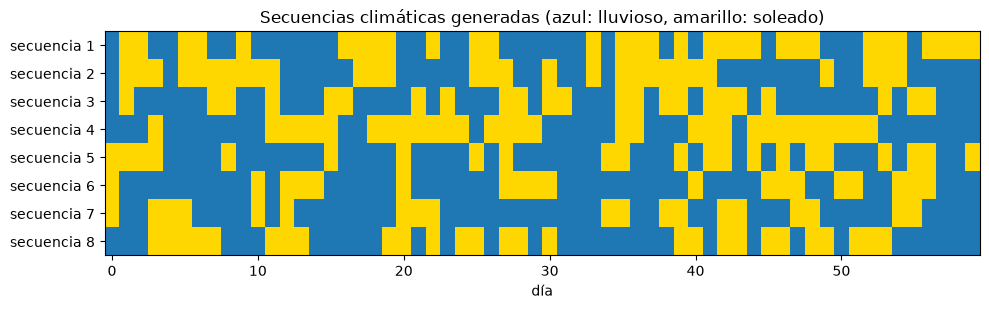

In [5]:
K, T = 8, 60
Q = muestrear_cadena(A, pi, K, T, rng)
print("Secuencia 1 (L = lluvioso, S = soleado):", "".join("LS"[i] for i in Q[0]))

plt.figure(figsize=(10, 3.2))
plt.imshow(Q, cmap=colores, aspect="auto", interpolation="nearest")
plt.yticks(range(K), [f"secuencia {k+1}" for k in range(K)]); plt.xlabel("día"); plt.grid(False)
plt.title("Secuencias climáticas generadas (azul: lluvioso, amarillo: soleado)")
plt.tight_layout(); plt.show()

Para comprobar el generador se simula una secuencia muy larga ($10^5$ días). La fracción de tiempo en cada estado debe tender a $\boldsymbol\pi^*=(4/7,\,3/7)$ y las frecuencias de transición a $\mathbf{A}$.

In [6]:
ql = muestrear_cadena(A, pi, 1, 100_000, rng)
Ah_l, _, _ = estimar_cadena(ql, 2)
print("π* teórica:", distribucion_estacionaria(A).round(4), "| fracción de tiempo simulada:", np.bincount(ql[0]) / ql.size)
print("Transiciones estimadas:\n", Ah_l.round(3))

π* teórica: [0.571 0.429] | fracción de tiempo simulada: [0.571 0.429]
Transiciones estimadas:
 [[0.701 0.299]
 [0.398 0.602]]


*La fracción de tiempo en cada estado en la secuencia larga, $(0.571,\,0.429)$, coincide con la distribución estacionaria $\boldsymbol\pi^*=(4/7,3/7)$, y las transiciones estimadas reproducen $\mathbf{A}$. Hay que distinguir $\boldsymbol\pi^*$ (a lo que tiende la fracción de tiempo) de $\boldsymbol\pi=(0.6,0.4)$, que es la distribución del primer día. En las secuencias no se ve ningún patrón regular y predominan las rachas cortas.*

### 1c. Re-estimación de $\mathbf{A}$ y $\boldsymbol\pi$

Se estiman por conteo a partir de secuencias generadas. Primero, una secuencia de 100 días y 50 secuencias de 100 días:

In [7]:
for K_, T_ in [(1, 100), (50, 100)]:
    Ah, ph, _ = estimar_cadena(muestrear_cadena(A, pi, K_, T_, rng), 2)
    print(f"K = {K_} secuencia(s) de T = {T_} días:  Â =", Ah.round(3).tolist(), " π̂ =", ph.round(3))
print("Valores reales:                           A =", A.tolist(), " π =", pi.tolist())

K = 1 secuencia(s) de T = 100 días:  Â = [[0.655, 0.345], [0.432, 0.568]]  π̂ = [0. 1.]
K = 50 secuencia(s) de T = 100 días:  Â = [[0.689, 0.311], [0.41, 0.59]]  π̂ = [0.58 0.42]
Valores reales:                           A = [[0.7, 0.3], [0.4, 0.6]]  π = [0.6, 0.4]


Para ver cómo influyen la cantidad $K$ y el largo $T$ de las secuencias, se estiman los parámetros con $K\in\{1,5,20,100\}$ y $T\in\{5,20,100,500\}$, repitiendo cada configuración 300 veces. Se muestra el error absoluto medio de las entradas de $\hat{\mathbf{A}}$ y de $\hat{\boldsymbol\pi}$.

,T=5,T=20,T=100,T=500
error de Â,,,,
K=1,0.306,0.140,0.054,0.024
K=5,0.135,0.056,0.024,0.011
K=20,0.055,0.029,0.012,0.005
K=100,0.027,0.013,0.005,0.002


,T=5,T=20,T=100,T=500
error de π̂,,,,
K=1,0.485,0.469,0.479,0.484
K=5,0.191,0.179,0.167,0.175
K=20,0.089,0.084,0.088,0.077
K=100,0.042,0.038,0.038,0.039


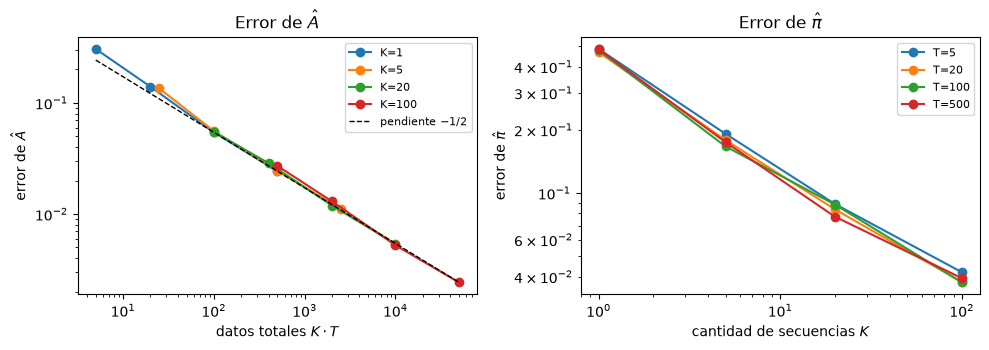

In [8]:
Ks, Ts, R = [1, 5, 20, 100], [5, 20, 100, 500], 300
errA, errP = np.zeros((4, 4)), np.zeros((4, 4))
for a, K_ in enumerate(Ks):
    for b, T_ in enumerate(Ts):
        e = [estimar_cadena(muestrear_cadena(A, pi, K_, T_, rng), 2)[:2] for _ in range(R)]
        errA[a, b] = np.nanmean([np.nanmean(np.abs(Ah - A)) for Ah, _ in e]); errP[a, b] = np.mean([np.abs(ph - pi).mean() for _, ph in e])

display(pd.DataFrame(errA, index=[f"K={k}" for k in Ks], columns=[f"T={t}" for t in Ts]).round(3).rename_axis("error de Â"))
display(pd.DataFrame(errP, index=[f"K={k}" for k in Ks], columns=[f"T={t}" for t in Ts]).round(3).rename_axis("error de π̂"))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for a, K_ in enumerate(Ks): axs[0].loglog(np.array(Ts) * K_, errA[a], "o-", label=f"K={K_}")
n_ref = np.array([5.0, 5e4]); axs[0].loglog(n_ref, errA[0, 2] * 10 / np.sqrt(n_ref), "k--", lw=1, label="pendiente −1/2")
axs[0].set(xlabel="datos totales $K\\cdot T$", ylabel="error de $\\hat{A}$", title="Error de $\\hat{A}$"); axs[0].legend(fontsize=8)
for b, T_ in enumerate(Ts): axs[1].loglog(Ks, errP[:, b], "o-", label=f"T={T_}")
axs[1].set(xlabel="cantidad de secuencias $K$", ylabel="error de $\\hat{\\pi}$", title="Error de $\\hat{\\pi}$"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

*Con una sola secuencia $\hat{\boldsymbol\pi}=(0,1)$, $\boldsymbol\pi$ se estima solo con el primer día de cada secuencia, así que con $K=1$ es una muestra de tamaño 1 (siempre da $(1,0)$ o $(0,1)$). Con 50 secuencias se obtiene $(0.58,0.42)$. En cambio $\hat{\mathbf{A}}$ ya es razonable con una secuencia, aunque ruidosa.*

*El error de $\hat{\mathbf{A}}$ depende de la cantidad total de transiciones $K\cdot T$ y no de cómo se reparten. Con unas 100 transiciones el error es $0.054$ ($K=1,T=100$), $0.056$ ($K=5,T=20$) y $0.055$ ($K=20,T=5$), y todas las configuraciones caen sobre la misma recta de pendiente $-1/2$ (error $\propto1/\sqrt{K\,T}$). El error de $\hat{\boldsymbol\pi}$, en cambio, depende solo de la cantidad de secuencias $K$ y no de su largo, es $\approx0.48$ con $K=1$ para cualquier $T$, $\approx0.18$ con $K=5$, $\approx0.09$ con $K=20$ y $\approx0.04$ con $K=100$ (decae aproximadamente como $1/\sqrt K$). Alargar las secuencias no ayuda a estimar $\boldsymbol\pi$, hay que observar más secuencias.*

**¿Sería este modelo válido para todas las estaciones del año?** No. El modelo supone una única matriz $\mathbf{A}$ constante en el tiempo y que el clima de mañana depende solo del de hoy. Pero el clima depende de la estación por ejemplo, en verano son más probables los días soleados y las rachas de sol, y en invierno las de lluvia. Una matriz estimada con datos de todo el año sería un promedio que no describe bien a ninguna estación.

### 1d. Modelo oculto de Markov

Para convertir la cadena en un HMM se deja de observar el clima y se agrega una matriz de observación $\mathbf{B}$, donde cada día se emite un símbolo cuya distribución depende del clima. $\mathbf{A}$ y $\boldsymbol\pi$ se conservan, y la simulación agrega un segundo sampleo por día (el símbolo dado el estado). Se parte de $\mathbf{B}=\mathbf{I}$ (el clima se observa sin error, que es la cadena anterior) y se lo oculta con
$$
\mathbf{B}_\varepsilon=\begin{pmatrix}1-\varepsilon&\varepsilon\\ \varepsilon&1-\varepsilon\end{pmatrix},
$$
es decir, el símbolo coincide con el clima con probabilidad $1-\varepsilon$ (con $\varepsilon=0.5$ no dice nada del clima). Se simula con el mismo clima oculto:

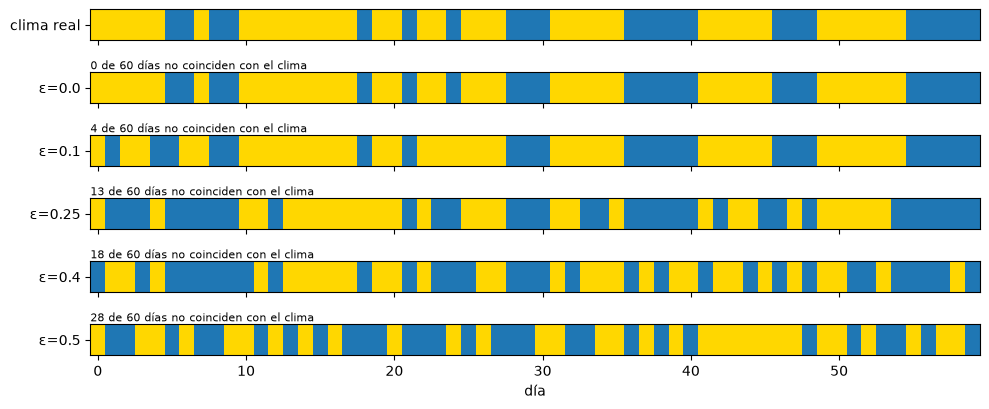

In [9]:
epsilons = [0.0, 0.1, 0.25, 0.4, 0.5]
q_oc = muestrear_cadena(A, pi, 1, 60, rng)[0]
fig, axs = plt.subplots(len(epsilons) + 1, 1, figsize=(10, 4.2), sharex=True)
axs[0].imshow(q_oc[None], cmap=colores, aspect="auto", interpolation="nearest"); axs[0].set_yticks([0]); axs[0].set_yticklabels(["clima real"]); axs[0].grid(False)
for ax, e in zip(axs[1:], epsilons):
    Be = np.array([[1 - e, e], [e, 1 - e]])
    Oe = (rng.random(60)[:, None] > np.cumsum(Be, 1)[q_oc][:, :-1]).sum(1)
    ax.imshow(Oe[None], cmap=colores, aspect="auto", interpolation="nearest"); ax.set_yticks([0]); ax.set_yticklabels([f"ε={e}"]); ax.grid(False)
    ax.set_title(f"{int((Oe != q_oc).sum())} de 60 días no coinciden con el clima", fontsize=8, loc="left", pad=2)
axs[-1].set_xlabel("día"); plt.tight_layout(); plt.show()

Con 100 secuencias de 200 días se compara, para cada $\varepsilon$, qué fracción de los símbolos coincide con el clima real y el error de $\hat{\mathbf{A}}$ si se lo estima ignorando que el clima está oculto (contando transiciones entre símbolos, como en el caso observable).

In [10]:
filas = []
for e in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    Be = np.array([[1 - e, e], [e, 1 - e]])
    q_, O_ = muestrear_hmm(A, Be, pi, 100, 200, rng)
    filas.append({"ε": e, "símbolos que coinciden con el clima": (O_ == q_).mean(),
                  "error de Â contando transiciones entre símbolos": np.abs(estimar_cadena(O_, 2)[0] - A).mean()})
display(pd.DataFrame(filas).set_index("ε").round(3))

,símbolos que coinciden con el clima,error de Â contando transiciones entre símbolos
ε,,
0.0,1.000,0.001
0.1,0.900,0.060
0.2,0.800,0.099
0.3,0.701,0.129
0.4,0.609,0.138
0.5,0.502,0.150


*Con $\varepsilon=0$ lo observado es el clima (la cadena anterior). A medida que crece $\varepsilon$, los símbolos coinciden cada vez menos con el clima y las secuencias observadas pasan a tener rachas más cortas que las del clima. Además, si se estima $\mathbf{A}$ contando transiciones entre símbolos, como en el caso observable, el error crece de $0.001$ a $0.150$, la secuencia observada ya no es una cadena de Markov con matriz $\mathbf{A}$, porque el ruido de observación borra la persistencia del clima (con $\varepsilon=0.5$ las filas estimadas tienden a $(0.5,0.5)$). Por eso en un modelo oculto hacen falta algoritmos que tengan en cuenta la emisión, como Viterbi (2a) y Baum-Welch (2b).*

### 2a. Secuencia de climas más probable

Con el HMM de la guía (3 símbolos) se genera una secuencia de 2000 días de comportamientos y se calcula con Viterbi la secuencia de climas más probable. Como el simulador guarda el clima verdadero, se puede medir cuánto difiere.

Primeros 60 días (C = caminar, B = comprar, M = museo; L = lluvioso, S = soleado):
  comportamiento: CCCMCMMMMBMMMMMMMCCBCMMCMMBMMCBBBBBCBBCBCBMBCCBBMBMCBMBCBMCM
  clima real    : SSSLSLSLLLLLLLLLLSSSSSLSLLLLLSSSSSLSSSSSSLLSSSSSLLSSLSSSLLSL
  clima Viterbi : SSSLSLLLLLLLLLLLLSSSSLLSLLLLLSLLLLLSSSSSSLLLSSLLLLLSLLLSLLSL

Días en que Viterbi difiere del clima real: 457 de 2000  → acierto 77.1%
Acierto de la línea de base (siempre el estado más frecuente): 57.0%
Error por estado real: {'Lluvioso': '14.7%', 'Soleado': '33.6%'}
log P(O, camino de Viterbi) = -2668.5   |   log P(O, camino real) = -3154.2


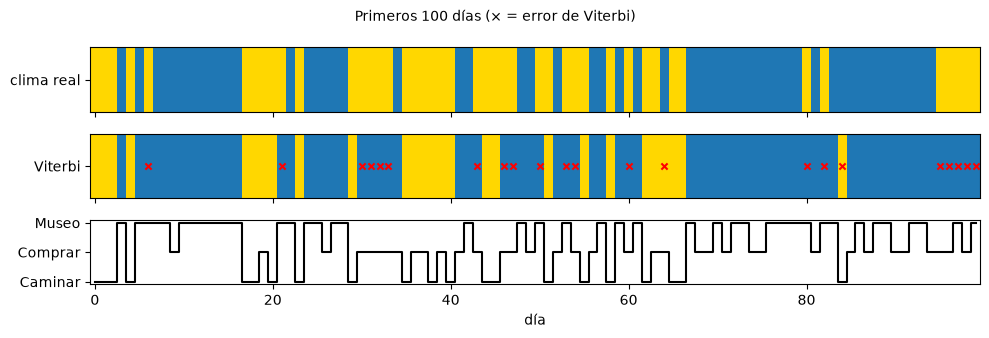

In [11]:
T_a = 2000
q_r, O_r = muestrear_hmm(A, B, pi, 1, T_a, rng)
q_v, lp_v = viterbi(A, B, pi, O_r)
q_r, O_r, q_v = q_r[0], O_r[0], q_v[0]
lp_real = np.log(pi[q_r[0]] * B[q_r[0], O_r[0]]) + np.sum(np.log(A[q_r[:-1], q_r[1:]] * B[q_r[1:], O_r[1:]]))

print("Primeros 60 días (C = caminar, B = comprar, M = museo; L = lluvioso, S = soleado):")
print("  comportamiento:", "".join("CBM"[o] for o in O_r[:60]))
print("  clima real    :", "".join("LS"[i] for i in q_r[:60]))
print("  clima Viterbi :", "".join("LS"[i] for i in q_v[:60]))
print(f"\nDías en que Viterbi difiere del clima real: {int((q_v != q_r).sum())} de {T_a}  → acierto {(q_v == q_r).mean():.1%}")
print(f"Acierto de la línea de base (siempre el estado más frecuente): {max((q_r == 0).mean(), (q_r == 1).mean()):.1%}")
print("Error por estado real:", {ESTADOS[i]: f"{(q_v[q_r == i] != i).mean():.1%}" for i in range(2)})
print(f"log P(O, camino de Viterbi) = {lp_v[0]:.1f}   |   log P(O, camino real) = {lp_real:.1f}")

n = 100
fig, axs = plt.subplots(3, 1, figsize=(10, 3.4), sharex=True)
for ax, (q_, nom) in zip(axs[:2], [(q_r, "clima real"), (q_v, "Viterbi")]):
    ax.imshow(q_[None, :n], cmap=colores, aspect="auto", interpolation="nearest"); ax.set_yticks([0]); ax.set_yticklabels([nom]); ax.grid(False)
err = np.flatnonzero(q_v[:n] != q_r[:n]); axs[1].scatter(err, np.zeros(len(err)), marker="x", c="red", s=20)
axs[2].step(range(n), O_r[:n], where="mid", color="k"); axs[2].set_yticks(range(3)); axs[2].set_yticklabels(SIMBOLOS); axs[2].set_xlabel("día")
plt.suptitle("Primeros 100 días (× = error de Viterbi)", fontsize=10); plt.tight_layout(); plt.show()

*Viterbi acierta el clima en el 77.1% de los 2000 días, frente a 57% de la línea de base (siempre "lluvioso"). El error es asimétrico, 14.7% de los días lluviosos y 33.6% de los soleados, porque un día soleado con "comprar" o "museo" se explica mejor como lluvioso, y además la lluvia es más frecuente. En la figura se ve que Viterbi "alisa" la secuencia y los errores se concentran en las rachas cortas.*

*La diferencia con el clima real no es un defecto del algoritmo, $\log P(O,\mathbf{q}^*)=-2669$ es mucho mayor que la de la secuencia real ($-3154$). Viterbi encuentra la secuencia más probable según el modelo, no la verdadera, y una realización real contiene sucesos poco probables (como rachas de un solo día). Con emisiones que se superponen tanto, algunos días no se pueden distinguir con la información de las observaciones.*

### 2b. Entrenamiento con Viterbi y con Baum-Welch

Se generan $K=30$ secuencias adicionales de $T=100$ días y se estiman los parámetros solo a partir de las observaciones con ambos métodos. Como los dos dependen de la inicialización, cada uno se ejecuta con 10 inicios aleatorios y se conserva el mejor según su propio criterio.

In [12]:
q_tr, O_tr = muestrear_hmm(A, B, pi, 30, 100, rng)
ll_real = log_verosimilitud(A, B, pi, O_tr).sum()
mejor_bw, res_bw = ajustar(O_tr, baum_welch, 10, rng)
mejor_vt, res_vt = ajustar(O_tr, entrenar_viterbi, 10, rng)

print(f"log P(O) con los parámetros reales: {ll_real:.1f}")
print("Baum-Welch, log P(O) final de cada inicio:", sorted(round(float(r[3][-1]), 1) for r in res_bw))
print("   ¿log-verosimilitud no decreciente en todas las corridas?", all(np.all(np.diff(r[3]) > -1e-8) for r in res_bw))
print("Viterbi, log P(O) (con el modelo final) de cada inicio:", sorted(round(float(log_verosimilitud(*r[:3], O_tr).sum()), 1) for r in res_vt))
print(f"log P(O) del mejor ajuste de cada método:  Baum-Welch = {log_verosimilitud(*mejor_bw[:3], O_tr).sum():.1f}   Viterbi = {log_verosimilitud(*mejor_vt[:3], O_tr).sum():.1f}")

est = {"BW": alinear(mejor_bw), "Viterbi": alinear(mejor_vt)}
filas = {"real": [*A.ravel(), *B.ravel(), *pi]}
for nom, (Ah, Bh, ph) in est.items():
    filas[nom] = [*Ah.ravel(), *Bh.ravel(), *ph]
nombres_p = [f"a({ESTADOS[i][0]}→{ESTADOS[j][0]})" for i in range(2) for j in range(2)] + [f"b({ESTADOS[i][0]}, {SIMBOLOS[k]})" for i in range(2) for k in range(3)] + [f"π({e[0]})" for e in ESTADOS]
tab = pd.DataFrame(filas, index=nombres_p)
tab["|BW − real|"] = (tab["BW"] - tab["real"]).abs(); tab["|Viterbi − real|"] = (tab["Viterbi"] - tab["real"]).abs()
display(tab.round(3))
print("Error medio absoluto  BW:", tab["|BW − real|"].mean().round(3), "  Viterbi:", tab["|Viterbi − real|"].mean().round(3))

log P(O) con los parámetros reales: -3273.5
Baum-Welch, log P(O) final de cada inicio: [-3294.2, -3294.1, -3294.0, -3293.8, -3293.8, -3293.8, -3270.8, -3270.5, -3270.4, -3270.2]
   ¿log-verosimilitud no decreciente en todas las corridas? True
Viterbi, log P(O) (con el modelo final) de cada inicio: [-3451.0, -3381.3, -3298.1, -3294.2, -3294.2, -3294.2, -3294.2, -3294.2, -3293.2, -3277.5]
log P(O) del mejor ajuste de cada método:  Baum-Welch = -3270.2   Viterbi = -3277.5


,real,BW,Viterbi,|BW − real|,|Viterbi − real|
a(L→L),0.7,0.606,0.705,0.094,0.005
a(L→S),0.3,0.394,0.295,0.094,0.005
a(S→L),0.4,0.284,0.600,0.116,0.200
a(S→S),0.6,0.716,0.400,0.116,0.200
"b(L, Caminar)",0.1,0.019,0.000,0.081,0.100
"b(L, Comprar)",0.4,0.399,0.519,0.001,0.119
"b(L, Museo)",0.5,0.582,0.481,0.082,0.019
"b(S, Caminar)",0.6,0.553,1.000,0.047,0.400
"b(S, Comprar)",0.3,0.312,0.000,0.012,0.300
"b(S, Museo)",0.1,0.134,0.000,0.034,0.100


Error medio absoluto  BW: 0.057   Viterbi: 0.149


*Con Baum-Welch la log-verosimilitud no decreció en ninguna iteración (propiedad del EM), pero solo 4 de los 10 inicios llegaron al mejor máximo, los otros 6 quedaron en un máximo local peor. Hace falta probar varios inicios. Los parámetros estimados quedan cerca de los reales.*

*El entrenamiento de Viterbi llega a una solución peor, con error medio de $0.149$, con $\hat{\mathbf{B}}$ degenerada (Soleado emite solo "Caminar" con probabilidad 1 y Lluvioso solo "Comprar" o "Museo"), $\hat{\mathbf{A}}=\begin{pmatrix}0.71&0.30\\0.60&0.40\end{pmatrix}$ con la fila de Soleado muy distinta de la real, y un $\log P(O)$ peor que el de Baum-Welch ($-3277.5$ contra $-3270.2$). El motivo es que maximiza $P(O,\mathbf{q}\mid\lambda)$ conjuntamente en los parámetros y en los caminos, lo que favorece emisiones deterministas aunque expliquen peor los datos, mientras que Baum-Welch maximiza $P(O\mid\lambda)$ con asignaciones blandas.*

Como el resultado de una sola muestra es ruidoso, se repite con $K\in\{5,30,100\}$ secuencias (de $T=100$ días), 8 repeticiones de cada una y 5 inicios por ajuste, y se promedia el error absoluto medio de $\hat{\mathbf{A}}$, $\hat{\mathbf{B}}$ y $\hat{\boldsymbol\pi}$.

In [13]:
filas = []
for K_ in [5, 30, 100]:
    for _ in range(8):
        _, O_ = muestrear_hmm(A, B, pi, K_, 100, rng)
        for nom, fn in [("Baum-Welch", baum_welch), ("Viterbi", entrenar_viterbi)]:
            Ah, Bh, ph = alinear(ajustar(O_, fn, 5, rng)[0])
            filas.append({"método": nom, "K": K_, "A": np.abs(Ah - A).mean(), "B": np.abs(Bh - B).mean(), "π": np.abs(ph - pi).mean()})
display(pd.DataFrame(filas).groupby(["método", "K"]).agg(["mean", "std"]).round(3))

A             B             π       
                 mean    std   mean    std   mean    std
método     K                                            
Baum-Welch 5    0.177  0.091  0.124  0.083  0.385  0.232
           30   0.093  0.061  0.064  0.029  0.221  0.142
           100  0.085  0.030  0.048  0.015  0.083  0.070
Viterbi    5    0.378  0.219  0.199  0.076  0.400  0.107
           30   0.329  0.226  0.171  0.016  0.308  0.197
           100  0.367  0.239  0.215  0.070  0.280  0.143

*Baum-Welch mejora de $K=5$ a $K=30$, y de $K=30$ a $K=100$ la mejora es pequeña en $\hat{\mathbf{A}}$ y algo mayor en $\hat{\mathbf{B}}$, mientras que $\hat{\boldsymbol\pi}$ sigue bajando. La estimación de $\mathbf{A}$ converge lentamente. El entrenamiento de Viterbi tiene errores de entre 3 y 4.5 veces los de Baum-Welch en $\hat{\mathbf{A}}$ y $\hat{\mathbf{B}}$ para $K\ge30$ y no mejora al agregar datos. Es un estimador sesgado, que no converge a los parámetros reales aunque haya más datos. Solo resulta razonable cuando los estados se distinguen bien por sus emisiones, y acá se superponen mucho.*

### 2c. Clasificación de un turista según su primera semana

Se tiene un HMM $\lambda_k=(\mathbf{A},\mathbf{B}_k,\boldsymbol\pi)$ por cada tipo de turista $k$, entrenado de antemano con Baum-Welch usando secuencias de turistas de tipo conocido. Para un turista nuevo con actividades $O_1,\dots,O_7$ se calcula con forward la verosimilitud $P(O\mid\lambda_k)$ bajo cada modelo y se lo asigna al tipo de mayor verosimilitud (si se conocen las proporciones de cada tipo, al de mayor $\log P(O\mid\lambda_k)+\log P(k)$, por Bayes).

Para probarlo se usan tres tipos de turista (el clima es el mismo y cambia el comportamiento ante cada clima):

| Tipo | Lluvioso: Caminar / Comprar / Museo | Soleado: Caminar / Comprar / Museo |
|:--|:-:|:-:|
| **Estándar** (el de la guía) | 0.10 / 0.40 / 0.50 | 0.60 / 0.30 / 0.10 |
| **Caminante** | 0.50 / 0.15 / 0.35 | 0.85 / 0.10 / 0.05 |
| **Comprador** | 0.05 / 0.60 / 0.35 | 0.25 / 0.65 / 0.10 |

In [ ]:
TIPOS = {"Estándar": B,
         "Caminante": np.array([[0.50, 0.15, 0.35], [0.85, 0.10, 0.05]]),
         "Comprador": np.array([[0.05, 0.60, 0.35], [0.25, 0.65, 0.10]])}
tipos = list(TIPOS)


def clasificar(O, log_prior=None):
    ll = np.stack([log_verosimilitud(A, TIPOS[t], pi, O) for t in tipos], axis=1)
    if log_prior is not None: ll = ll + log_prior
    return ll.argmax(1), ll


_, O_ej = muestrear_hmm(A, TIPOS["Caminante"], pi, 1, 7, rng)
k_, ll_ = clasificar(O_ej)
print("Primera semana de un turista (tipo real: Caminante):", [SIMBOLOS[o] for o in O_ej[0]])
print("log P(O | tipo):", {t: round(float(v), 2) for t, v in zip(tipos, ll_[0])}, "→ clasificado como:", tipos[k_[0]])

Primera semana de un turista (tipo real: Caminante): ['Museo', 'Caminar', 'Comprar', 'Comprar', 'Caminar', 'Museo', 'Comprar']
log P(O | tipo): {'Estándar': -7.94, 'Caminante': -10.06, 'Comprador': -8.44} → clasificado como: Estándar


Para medir el desempeño se generan 500 turistas de cada tipo y se clasifican según los primeros $T$ días, con $T$ entre 1 y 30.

Matriz de confusión a los 7 días (filas = tipo real, columnas = tipo asignado):


,Estándar,Caminante,Comprador
Estándar,0.58,0.20,0.23
Caminante,0.18,0.82,0.00
Comprador,0.25,0.01,0.74


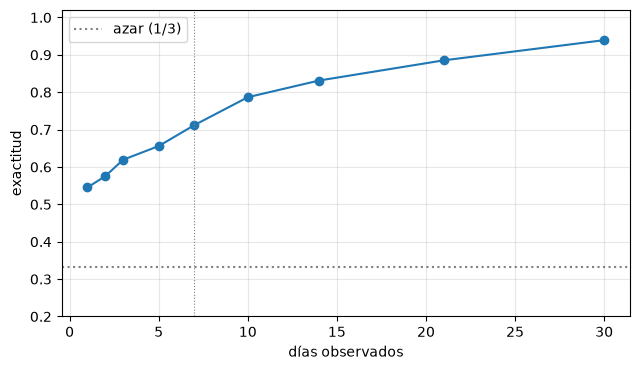

Exactitud: {1: 0.545, 2: 0.575, 3: 0.619, 5: 0.656, 7: 0.712, 10: 0.787, 14: 0.831, 21: 0.885, 30: 0.939}


In [15]:
largos = [1, 2, 3, 5, 7, 10, 14, 21, 30]
acc, conf7 = [], None
for T_ in largos:
    conf = np.zeros((3, 3))
    for k, t in enumerate(tipos):
        pred, _ = clasificar(muestrear_hmm(A, TIPOS[t], pi, 500, T_, rng)[1])
        conf[k] = np.bincount(pred, minlength=3) / 500
    acc.append(np.diag(conf).mean())
    if T_ == 7: conf7 = conf

print("Matriz de confusión a los 7 días (filas = tipo real, columnas = tipo asignado):")
display(pd.DataFrame(conf7, index=tipos, columns=tipos).round(2))

plt.figure(figsize=(6.5, 3.8))
plt.plot(largos, acc, "o-"); plt.axhline(1 / 3, color="gray", ls=":", label="azar (1/3)"); plt.axvline(7, color="gray", ls=":", lw=0.8)
plt.xlabel("días observados"); plt.ylabel("exactitud"); plt.ylim(0.2, 1.02); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()
print("Exactitud:", {d: round(float(a), 3) for d, a in zip(largos, acc)})

*Con una semana de observación la exactitud es 71.2% (frente a 33 % del azar). El tipo más fácil de reconocer es el *Caminante* (82 %) y el más difícil el *Estándar* (58 %), cuyo comportamiento queda entre los otros dos. La exactitud crece con los días observados, así que una semana da información útil pero no concluyente. Estos valores son una cota superior, porque se usaron los modelos verdaderos.*

### Conclusiones

1. El modelo generativo ($q_1\sim\boldsymbol\pi$, $q_{t+1}\sim\mathbf{A}_{q_t,\cdot}$) reproduce la distribución estacionaria $\boldsymbol\pi^*=(4/7,3/7)$ y la matriz de transición.
2. $\hat{\mathbf{A}}$ mejora con la cantidad total de transiciones $K\cdot T$ (error $\propto1/\sqrt{KT}$), mientras que $\hat{\boldsymbol\pi}$ mejora solo con la cantidad de secuencias $K$. El modelo, con una matriz constante, no es válido para todas las estaciones (una única $\mathbf{A}$ sería un promedio que ajusta mal cada una).
3. El modelo oculto se obtiene agregando una matriz de observación $\mathbf{B}$. Al ocultar el estado, los símbolos coinciden cada vez menos con el clima y estimar $\mathbf{A}$ contando transiciones entre símbolos da resultados sesgados.
4. Viterbi acierta el 77.1 % del clima real (contra 57.0 % de la línea de base) y se equivoca más en los días soleados (34 %) que en los lluviosos (15 %). Su secuencia es más probable que la real. La diferencia se debe a la información limitada de las observaciones y no nocesariamente a un error del algoritmo.
5. Baum-Welch estima razonablemente los parámetros, con log-verosimilitud monótona, pero necesita varios inicios (4 de 10 llegaron al mejor máximo) y $\mathbf{A}$ converge lento. El entrenamiento de Viterbi es más rápido pero sesgado.
6. Para clasificar se asigna el turista al tipo cuyo modelo da mayor $P(O\mid\lambda_k)$, calculado con forward (con un a priori $\log P(k)$ si se conoce).